In [1]:
import configparser
import os

import numpy as np
import pandas as pd

In [ ]:
os.chdir('../')

In [2]:
dataset = 'all_noHypoHyper'

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('../data.ini')
data = data['DEFAULT']

## Load

In [4]:
driverml = pd.read_csv("../" + data[f'driverml___{dataset}___out'], sep='\t', engine='python', comment='#')
driverml_RAS = pd.read_csv("../" + data[f'driverml___{dataset}_RAS___out'], sep='\t', engine='python', comment='#')
driverml_nonRAS = pd.read_csv("../" + data[f'driverml___{dataset}_nonRAS___out'], sep='\t', engine='python', comment='#')

In [5]:
driverml

,gene,total,silent,missense,nonsense,splicing,Fs_indel,nFs_indel,LRT,p,p_adj
0,APC,1069,13,81,641,0,334,0,16189.078989,0.000000e+00,0.000000
1,TP53,661,3,504,79,0,67,8,3598.049075,0.000000e+00,0.000000
2,PLEKHA6,69,12,20,3,0,34,0,1878.264983,5.663480e-07,0.003333
3,BRAF,183,3,176,2,0,2,0,1577.764718,1.767000e-06,0.007800
4,KRAS,426,10,414,0,0,1,1,1461.222220,2.038850e-06,0.007200
...,...,...,...,...,...,...,...,...,...,...,...
17652,ENTPD2,23,4,11,1,0,7,0,-0.009541,9.993640e-01,0.999591
17653,SELL,6,3,2,0,0,1,0,0.009290,9.993800e-01,0.999550
17654,TMCO5A,9,2,7,0,0,0,0,0.007703,9.994870e-01,0.999600
17655,PAM16,4,1,2,0,0,1,0,0.001903,9.998740e-01,0.999931


## p-value analysis

In [6]:
pv_qfreq = 0.01

In [7]:
numGenes_pvLower = pd.DataFrame(
    [(i, len(driverml.loc[driverml['p'] <= i, 'gene'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
numGenes_pvLower_RAS = pd.DataFrame(
    [(i, len(driverml_RAS.loc[driverml_RAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)
numGenes_pvLower_nonRAS = pd.DataFrame(
    [(i, len(driverml_nonRAS.loc[driverml_nonRAS['p'] <= i, 'gene'])) for i in np.clip(np.arange(pv_qfreq, 1+pv_qfreq, pv_qfreq), a_min=0, a_max=1)],
    columns=['p-value', 'numGenes']
)

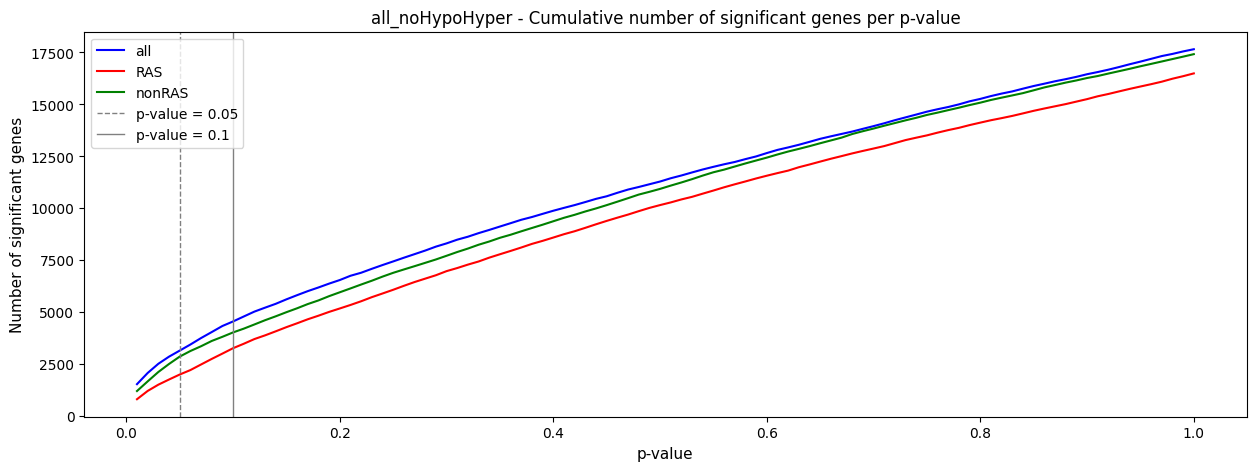

In [8]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes per p-value')
plt.plot(numGenes_pvLower.set_index('p-value'), label='all', color='blue')
plt.plot(numGenes_pvLower_RAS.set_index('p-value'), label='RAS', color='red')
plt.plot(numGenes_pvLower_nonRAS.set_index('p-value'), label='nonRAS', color='green')
plt.axvline(x=0.05, color='grey', linestyle='--', linewidth=1, label='p-value = 0.05')
plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='p-value = 0.1')
plt.xlabel('p-value', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_driverML_cumulativeNumSignificantGenes_perPV.png')
plt.show()

In [9]:
numGenes_pvLower.head(10)

,p-value,numGenes
0,0.01,1542
1,0.02,2080
2,0.03,2522
3,0.04,2865
4,0.05,3156
5,0.06,3448
6,0.07,3760
7,0.08,4048
8,0.09,4340
9,0.10,4559


In [10]:
genes_all_pv01 = driverml.loc[driverml['p'] < 0.1, 'gene']
genes_all_pv005 = driverml.loc[driverml['p'] < 0.05, 'gene']

genes_RAS_pv01 = driverml_RAS.loc[driverml_RAS['p'] < 0.1, 'gene']
genes_RAS_pv005 = driverml_RAS.loc[driverml_RAS['p'] < 0.05, 'gene']

genes_nonRAS_pv01 = driverml_nonRAS.loc[driverml_nonRAS['p'] < 0.1, 'gene']
genes_nonRAS_pv005 = driverml_nonRAS.loc[driverml_nonRAS['p'] < 0.05, 'gene']

In [11]:
print('all:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t\t' + str(genes_all_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t\t' + str(genes_all_pv005.count()))
print()
print('RAS:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t\t' + str(genes_RAS_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t\t' + str(genes_RAS_pv005.count()))
print()
print('nonRAS:')
print('Number of significant genes with p-value < 0.1:\t\t\t\t\t' + str(genes_nonRAS_pv01.count()))
print('Number of significant genes with p-value < 0.05:\t\t\t\t' + str(genes_nonRAS_pv005.count()))

all:
Number of significant genes with p-value < 0.1:					4559
Number of significant genes with p-value < 0.05:				3156

RAS:
Number of significant genes with p-value < 0.1:					3272
Number of significant genes with p-value < 0.05:				2005

nonRAS:
Number of significant genes with p-value < 0.1:					4031
Number of significant genes with p-value < 0.05:				2867


In [12]:
commonGenes_all_RAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005))
commonGenes_all_RAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01))

commonGenes_all_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_all_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_RAS_nonRAS_pv005 = set(genes_RAS_pv005).intersection(set(genes_nonRAS_pv005))
commonGenes_RAS_nonRAS_pv01 = set(genes_RAS_pv01).intersection(set(genes_nonRAS_pv01))

commonGenes_all_RAS_nonRAS_pv005 = set(genes_all_pv005).intersection(set(genes_RAS_pv005)).intersection(set(genes_nonRAS_pv005))
commonGenes_all_RAS_nonRAS_pv01 = set(genes_all_pv01).intersection(set(genes_RAS_pv01)).intersection(set(genes_nonRAS_pv01))

In [13]:
print('all ∩ RAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_RAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_RAS_pv01)))
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv01)))
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv01)))
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005)))
print('Number of common significant genes with p-value < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01)))

all ∩ RAS:
Number of common significant genes with p-value < 0.05:	1414
Number of common significant genes with p-value < 0.1:	2230

all ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	2122
Number of common significant genes with p-value < 0.1:	3144

RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	725
Number of common significant genes with p-value < 0.1:	1316

all ∩ RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.05:	684
Number of common significant genes with p-value < 0.1:	1177


In [14]:
genes_RAS_notIn_nonRAS_pv005 = set(genes_RAS_pv005).difference(set(genes_nonRAS_pv005))
genes_RAS_notIn_nonRAS_pv01 = set(genes_RAS_pv01).difference(set(genes_nonRAS_pv01))

genes_nonRAS_notIn_RAS_pv005 = set(genes_nonRAS_pv005).difference(set(genes_RAS_pv005))
genes_nonRAS_notIn_RAS_pv01 = set(genes_nonRAS_pv01).difference(set(genes_RAS_pv01))

nonCommonGenes_RAS_nonRAS_pv005 = genes_RAS_notIn_nonRAS_pv005.union(genes_nonRAS_notIn_RAS_pv005)
nonCommonGenes_RAS_nonRAS_pv01 = genes_RAS_notIn_nonRAS_pv01.union(genes_nonRAS_notIn_RAS_pv01)

In [15]:
print('RAS \\ nonRAS:')
print('Number of significant genes with p-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv005)))
print('Number of significant genes with p-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pv01)))
print()
print('nonRAS \\ RAS:')
print('Number of significant genes with p-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv005)))
print('Number of significant genes with p-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pv01)))
print()
print('RAS Δ nonRAS:')
print('Number of significant genes with p-value < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005)))
print('Number of significant genes with p-value < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01)))

RAS \ nonRAS:
Number of significant genes with p-value < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:		1280
Number of significant genes with p-value < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:		1956

nonRAS \ RAS:
Number of significant genes with p-value < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:		2142
Number of significant genes with p-value < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:		2715

RAS Δ nonRAS:
Number of significant genes with p-value < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:	3422
Number of significant genes with p-value < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:	4671


## pAdj-value analysis

In [16]:
pAdj_qfreq = 0.01

In [17]:
numGenes_pAdjLower = pd.DataFrame(
    [(i, len(driverml.loc[driverml['p_adj'] <= i, 'gene'])) for i in np.clip(np.arange(pAdj_qfreq, 1+pAdj_qfreq, pAdj_qfreq), a_min=0, a_max=1)],
    columns=['pAdj', 'numGenes']
)
numGenes_pAdjLower_RAS = pd.DataFrame(
    [(i, len(driverml_RAS.loc[driverml_RAS['p_adj'] <= i, 'gene'])) for i in np.clip(np.arange(pAdj_qfreq, 1+pAdj_qfreq, pAdj_qfreq), a_min=0, a_max=1)],
    columns=['pAdj', 'numGenes']
)
numGenes_pAdjLower_nonRAS = pd.DataFrame(
    [(i, len(driverml_nonRAS.loc[driverml_nonRAS['p_adj'] <= i, 'gene'])) for i in np.clip(np.arange(pAdj_qfreq, 1+pAdj_qfreq, pAdj_qfreq), a_min=0, a_max=1)],
    columns=['pAdj', 'numGenes']
)

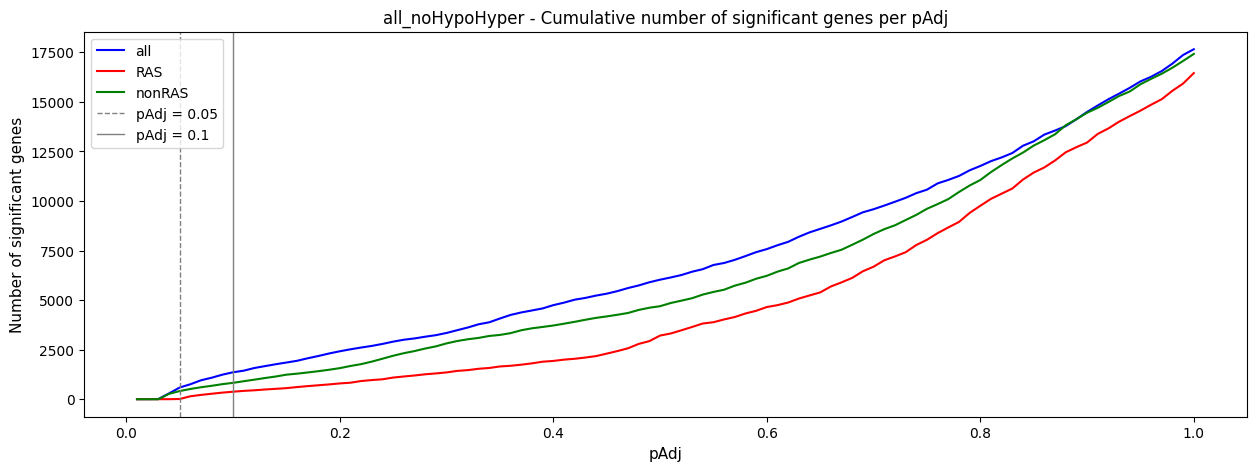

In [18]:
# plot
plt.figure(figsize=(15, 5))
plt.title(dataset + ' - Cumulative number of significant genes per pAdj')
plt.plot(numGenes_pAdjLower.set_index('pAdj'), label='all', color='blue')
plt.plot(numGenes_pAdjLower_RAS.set_index('pAdj'), label='RAS', color='red')
plt.plot(numGenes_pAdjLower_nonRAS.set_index('pAdj'), label='nonRAS', color='green')
plt.axvline(x=0.05, color='grey', linestyle='--', linewidth=1, label='pAdj = 0.05')
plt.axvline(x=0.1, color='grey', linestyle='-', linewidth=1, label='pAdj = 0.1')
plt.xlabel('pAdj', fontsize=11)
plt.ylabel('Number of significant genes', fontsize=11)
plt.legend(loc='upper left', fontsize=10)
plt.savefig("../" + data[f'plots___{dataset}'] + dataset + '_driverML_cumulativeNumSignificantGenes_perPAdj.png')
plt.show()

In [19]:
numGenes_pAdjLower.head(10)

,pAdj,numGenes
0,0.01,8
1,0.02,9
2,0.03,12
3,0.04,295
4,0.05,593
5,0.06,758
6,0.07,959
7,0.08,1088
8,0.09,1242
9,0.10,1362


In [20]:
genes_all_pAdj01 = driverml.loc[driverml['p_adj'] < 0.1, 'gene']
genes_all_pAdj005 = driverml.loc[driverml['p_adj'] < 0.05, 'gene']

genes_RAS_pAdj01 = driverml_RAS.loc[driverml_RAS['p_adj'] < 0.1, 'gene']
genes_RAS_pAdj005 = driverml_RAS.loc[driverml_RAS['p_adj'] < 0.05, 'gene']

genes_nonRAS_pAdj01 = driverml_nonRAS.loc[driverml_nonRAS['p_adj'] < 0.1, 'gene']
genes_nonRAS_pAdj005 = driverml_nonRAS.loc[driverml_nonRAS['p_adj'] < 0.05, 'gene']

In [21]:
print('all:')
print('Number of significant genes with pAdj < 0.1:\t\t\t' + str(genes_all_pAdj01.count()))
print('Number of significant genes with pAdj < 0.05:\t\t\t' + str(genes_all_pAdj005.count()))
print()
print('RAS:')
print('Number of significant genes with pAdj < 0.1:\t\t\t' + str(genes_RAS_pAdj01.count()))
print('Number of significant genes with pAdj < 0.05:\t\t\t' + str(genes_RAS_pAdj005.count()))
print()
print('nonRAS:')
print('Number of significant genes with pAdj < 0.1:\t\t\t' + str(genes_nonRAS_pAdj01.count()))
print('Number of significant genes with pAdj < 0.05:\t\t\t' + str(genes_nonRAS_pAdj005.count()))

all:
Number of significant genes with pAdj < 0.1:			1362
Number of significant genes with pAdj < 0.05:			593

RAS:
Number of significant genes with pAdj < 0.1:			382
Number of significant genes with pAdj < 0.05:			14

nonRAS:
Number of significant genes with pAdj < 0.1:			829
Number of significant genes with pAdj < 0.05:			415


In [22]:
commonGenes_all_RAS_pAdj005 = set(genes_all_pAdj005).intersection(set(genes_RAS_pAdj005))
commonGenes_all_RAS_pAdj01 = set(genes_all_pAdj01).intersection(set(genes_RAS_pAdj01))

commonGenes_all_nonRAS_pAdj005 = set(genes_all_pAdj005).intersection(set(genes_nonRAS_pAdj005))
commonGenes_all_nonRAS_pAdj01 = set(genes_all_pAdj01).intersection(set(genes_nonRAS_pAdj01))

commonGenes_RAS_nonRAS_pAdj005 = set(genes_RAS_pAdj005).intersection(set(genes_nonRAS_pAdj005))
commonGenes_RAS_nonRAS_pAdj01 = set(genes_RAS_pAdj01).intersection(set(genes_nonRAS_pAdj01))

commonGenes_all_RAS_nonRAS_pAdj005 = set(genes_all_pAdj005).intersection(set(genes_RAS_pAdj005)).intersection(set(genes_nonRAS_pAdj005))
commonGenes_all_RAS_nonRAS_pAdj01 = set(genes_all_pAdj01).intersection(set(genes_RAS_pAdj01)).intersection(set(genes_nonRAS_pAdj01))

In [23]:
print('all ∩ RAS:')
print('Number of common significant genes with pAdj < 0.05:\t' + str(len(commonGenes_all_RAS_pAdj005)))
print('Number of common significant genes with pAdj < 0.1:\t' + str(len(commonGenes_all_RAS_pAdj01)))
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with pAdj < 0.05:\t' + str(len(commonGenes_all_nonRAS_pAdj005)))
print('Number of common significant genes with pAdj < 0.1:\t' + str(len(commonGenes_all_nonRAS_pAdj01)))
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with pAdj < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pAdj005)))
print('Number of common significant genes with pAdj < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pAdj01)))
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with pAdj < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pAdj005)))
print('Number of common significant genes with pAdj < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pAdj01)))

all ∩ RAS:
Number of common significant genes with pAdj < 0.05:	12
Number of common significant genes with pAdj < 0.1:	332

all ∩ nonRAS:
Number of common significant genes with pAdj < 0.05:	269
Number of common significant genes with pAdj < 0.1:	717

RAS ∩ nonRAS:
Number of common significant genes with pAdj < 0.05:	7
Number of common significant genes with pAdj < 0.1:	130

all ∩ RAS ∩ nonRAS:
Number of common significant genes with pAdj < 0.05:	6
Number of common significant genes with pAdj < 0.1:	121


In [24]:
genes_RAS_notIn_nonRAS_pAdj005 = set(genes_RAS_pAdj005).difference(set(genes_nonRAS_pAdj005))
genes_RAS_notIn_nonRAS_pAdj01 = set(genes_RAS_pAdj01).difference(set(genes_nonRAS_pAdj01))

genes_nonRAS_notIn_RAS_pAdj005 = set(genes_nonRAS_pAdj005).difference(set(genes_RAS_pAdj005))
genes_nonRAS_notIn_RAS_pAdj01 = set(genes_nonRAS_pAdj01).difference(set(genes_RAS_pAdj01))

nonCommonGenes_RAS_nonRAS_pAdj005 = genes_RAS_notIn_nonRAS_pAdj005.union(genes_nonRAS_notIn_RAS_pAdj005)
nonCommonGenes_RAS_nonRAS_pAdj01 = genes_RAS_notIn_nonRAS_pAdj01.union(genes_nonRAS_notIn_RAS_pAdj01)

In [25]:
print('RAS \\ nonRAS:')
print('Number of significant genes with pAdj < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pAdj005)))
print('Number of significant genes with pAdj < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:\t\t' + str(len(genes_RAS_notIn_nonRAS_pAdj01)))
print()
print('nonRAS \\ RAS:')
print('Number of significant genes with pAdj < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pAdj005)))
print('Number of significant genes with pAdj < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:\t\t' + str(len(genes_nonRAS_notIn_RAS_pAdj01)))
print()
print('RAS Δ nonRAS:')
print('Number of significant genes with pAdj < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pAdj005)))
print('Number of significant genes with pAdj < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:\t' + str(len(nonCommonGenes_RAS_nonRAS_pAdj01)))


RAS \ nonRAS:
Number of significant genes with pAdj < 0.05 in RAS-mutated patients but not in non RAS-mutated patients:		7
Number of significant genes with pAdj < 0.1 in RAS-mutated patients but not in non RAS-mutated patients:		252

nonRAS \ RAS:
Number of significant genes with pAdj < 0.05 in non RAS-mutated patients but not in RAS-mutated patients:		408
Number of significant genes with pAdj < 0.1 in non RAS-mutated patients but not in RAS-mutated patients:		699

RAS Δ nonRAS:
Number of significant genes with pAdj < 0.05 in RAS-mutated patients or non RAS-mutated patients but not in both:	415
Number of significant genes with pAdj < 0.1 in RAS-mutated patients or non RAS-mutated patients but not in both:	951


## p-value and pAdj analysis

In [26]:
# all ∩ RAS
commonGenes_all_RAS_pv01_pAdj01 = commonGenes_all_RAS_pv01.intersection(commonGenes_all_RAS_pAdj01)
commonGenes_all_RAS_pv01_pAdj005 = commonGenes_all_RAS_pv01.intersection(commonGenes_all_RAS_pAdj005)

commonGenes_all_RAS_pv005_pAdj01 = commonGenes_all_RAS_pv005.intersection(commonGenes_all_RAS_pAdj01)
commonGenes_all_RAS_pv005_pAdj005 = commonGenes_all_RAS_pv005.intersection(commonGenes_all_RAS_pAdj005)

# all ∩ nonRAS
commonGenes_all_nonRAS_pv01_pAdj01 = commonGenes_all_nonRAS_pv01.intersection(commonGenes_all_nonRAS_pAdj01)
commonGenes_all_nonRAS_pv01_pAdj005 = commonGenes_all_nonRAS_pv01.intersection(commonGenes_all_nonRAS_pAdj005)

commonGenes_all_nonRAS_pv005_pAdj01 = commonGenes_all_nonRAS_pv005.intersection(commonGenes_all_nonRAS_pAdj01)
commonGenes_all_nonRAS_pv005_pAdj005 = commonGenes_all_nonRAS_pv005.intersection(commonGenes_all_nonRAS_pAdj005)

# RAS ∩ nonRAS
commonGenes_RAS_nonRAS_pv01_pAdj01 = commonGenes_RAS_nonRAS_pv01.intersection(commonGenes_RAS_nonRAS_pAdj01)
commonGenes_RAS_nonRAS_pv01_pAdj005 = commonGenes_RAS_nonRAS_pv01.intersection(commonGenes_RAS_nonRAS_pAdj005)

commonGenes_RAS_nonRAS_pv005_pAdj01 = commonGenes_RAS_nonRAS_pv005.intersection(commonGenes_RAS_nonRAS_pAdj01)
commonGenes_RAS_nonRAS_pv005_pAdj005 = commonGenes_RAS_nonRAS_pv005.intersection(commonGenes_RAS_nonRAS_pAdj005)

# all ∩ RAS ∩ nonRAS
commonGenes_all_RAS_nonRAS_pv01_pAdj01 = commonGenes_all_RAS_nonRAS_pv01.intersection(commonGenes_all_RAS_nonRAS_pAdj01)
commonGenes_all_RAS_nonRAS_pv01_pAdj005 = commonGenes_all_RAS_nonRAS_pv01.intersection(commonGenes_all_RAS_nonRAS_pAdj005)

commonGenes_all_RAS_nonRAS_pv005_pAdj01 = commonGenes_all_RAS_nonRAS_pv005.intersection(commonGenes_all_RAS_nonRAS_pAdj01)
commonGenes_all_RAS_nonRAS_pv005_pAdj005 = commonGenes_all_RAS_nonRAS_pv005.intersection(commonGenes_all_RAS_nonRAS_pAdj005)

In [27]:
print('all ∩ RAS:')
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.1:\t' + str(len(commonGenes_all_RAS_pv01_pAdj01)))
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.05:\t' + str(len(commonGenes_all_RAS_pv01_pAdj005)))
print()
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.1:\t' + str(len(commonGenes_all_RAS_pv005_pAdj01)))
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.05:\t' + str(len(commonGenes_all_RAS_pv005_pAdj005)))
print()
print()
print('all ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv01_pAdj01)))
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv01_pAdj005)))
print()
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.1:\t' + str(len(commonGenes_all_nonRAS_pv005_pAdj01)))
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.05:\t' + str(len(commonGenes_all_nonRAS_pv005_pAdj005)))
print()
print()
print('RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv01_pAdj01)))
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv01_pAdj005)))
print()
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.1:\t' + str(len(commonGenes_RAS_nonRAS_pv005_pAdj01)))
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.05:\t' + str(len(commonGenes_RAS_nonRAS_pv005_pAdj005)))
print()
print()
print('all ∩ RAS ∩ nonRAS:')
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01_pAdj01)))
print('Number of common significant genes with p-value < 0.1 and pAdj < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv01_pAdj005)))
print()
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.1:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005_pAdj01)))
print('Number of common significant genes with p-value < 0.05 and pAdj < 0.05:\t' + str(len(commonGenes_all_RAS_nonRAS_pv005_pAdj005)))

all ∩ RAS:
Number of common significant genes with p-value < 0.1 and pAdj < 0.1:	332
Number of common significant genes with p-value < 0.1 and pAdj < 0.05:	12

Number of common significant genes with p-value < 0.05 and pAdj < 0.1:	332
Number of common significant genes with p-value < 0.05 and pAdj < 0.05:	12


all ∩ nonRAS:
Number of common significant genes with p-value < 0.1 and pAdj < 0.1:	717
Number of common significant genes with p-value < 0.1 and pAdj < 0.05:	269

Number of common significant genes with p-value < 0.05 and pAdj < 0.1:	717
Number of common significant genes with p-value < 0.05 and pAdj < 0.05:	269


RAS ∩ nonRAS:
Number of common significant genes with p-value < 0.1 and pAdj < 0.1:	130
Number of common significant genes with p-value < 0.1 and pAdj < 0.05:	7

Number of common significant genes with p-value < 0.05 and pAdj < 0.1:	130
Number of common significant genes with p-value < 0.05 and pAdj < 0.05:	7


all ∩ RAS ∩ nonRAS:
Number of common significant genes wit

In [28]:
# RAS (pv ∧ pAdj) - nonRAS (pv ∨ pAdj)
genes_RAS_notIn_nonRAS_pv01_pAdj01 = genes_RAS_notIn_nonRAS_pv01.intersection(genes_RAS_notIn_nonRAS_pAdj01)
genes_RAS_notIn_nonRAS_pv01_pAdj005 = genes_RAS_notIn_nonRAS_pv01.intersection(genes_RAS_notIn_nonRAS_pAdj005)

genes_RAS_notIn_nonRAS_pv005_pAdj01 = genes_RAS_notIn_nonRAS_pv005.intersection(genes_RAS_notIn_nonRAS_pAdj01)
genes_RAS_notIn_nonRAS_pv005_pAdj005 = genes_RAS_notIn_nonRAS_pv005.intersection(genes_RAS_notIn_nonRAS_pAdj005)

# nonRAS (pv ∧ pAdj) - RAS (pv ∨ pAdj)
genes_nonRAS_notIn_RAS_pv01_pAdj01 = genes_nonRAS_notIn_RAS_pv01.intersection(genes_nonRAS_notIn_RAS_pAdj01)
genes_nonRAS_notIn_RAS_pv01_pAdj005 = genes_nonRAS_notIn_RAS_pv01.intersection(genes_nonRAS_notIn_RAS_pAdj005)

genes_nonRAS_notIn_RAS_pv005_pAdj01 = genes_nonRAS_notIn_RAS_pv005.intersection(genes_nonRAS_notIn_RAS_pAdj01)
genes_nonRAS_notIn_RAS_pv005_pAdj005 = genes_nonRAS_notIn_RAS_pv005.intersection(genes_nonRAS_notIn_RAS_pAdj005)

# RAS Δ nonRAS (pv) ∩ RAS Δ nonRAS (pAdj)
nonCommonGenes_RAS_nonRAS_pv01_pAdj01 = nonCommonGenes_RAS_nonRAS_pv01.intersection(nonCommonGenes_RAS_nonRAS_pAdj01)
nonCommonGenes_RAS_nonRAS_pv01_pAdj005 = nonCommonGenes_RAS_nonRAS_pv01.intersection(nonCommonGenes_RAS_nonRAS_pAdj005)

nonCommonGenes_RAS_nonRAS_pv005_pAdj01 = nonCommonGenes_RAS_nonRAS_pv005.intersection(nonCommonGenes_RAS_nonRAS_pAdj01)
nonCommonGenes_RAS_nonRAS_pv005_pAdj005 = nonCommonGenes_RAS_nonRAS_pv005.intersection(nonCommonGenes_RAS_nonRAS_pAdj005)

# ---------------------------------
# NOT THE SAME AS:
# nonCommonGenes_RAS_nonRAS_pv01_pAdj1_b = genes_RAS_notIn_nonRAS_pv01_pAdj1.union(genes_nonRAS_notIn_RAS_pv01_pAdj1)
# nonCommonGenes_RAS_nonRAS_pv01_pAdj01_b = genes_RAS_notIn_nonRAS_pv01_pAdj01.union(genes_nonRAS_notIn_RAS_pv01_pAdj01)
# nonCommonGenes_RAS_nonRAS_pv01_pAdj005_b = genes_RAS_notIn_nonRAS_pv01_pAdj005.union(genes_nonRAS_notIn_RAS_pv01_pAdj005)
# nonCommonGenes_RAS_nonRAS_pv005_pAdj1_b = genes_RAS_notIn_nonRAS_pv005_pAdj1.union(genes_nonRAS_notIn_RAS_pv005_pAdj1)
# nonCommonGenes_RAS_nonRAS_pv005_pAdj01_b = genes_RAS_notIn_nonRAS_pv005_pAdj01.union(genes_nonRAS_notIn_RAS_pv005_pAdj01)
# nonCommonGenes_RAS_nonRAS_pv005_pAdj005_b = genes_RAS_notIn_nonRAS_pv005_pAdj005.union(genes_nonRAS_notIn_RAS_pv005_pAdj005)

In [29]:
print('RAS (pv ∧ pAdj) \\ nonRAS (pv ∨ pAdj)')
print('Number of significant genes with p-value < 0.1 AND pAdj < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR pAdj < 0.1:\t' + str(len(genes_RAS_notIn_nonRAS_pv01_pAdj01)))
print('Number of significant genes with p-value < 0.1 AND pAdj < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR pAdj < 0.05:\t' + str(len(genes_RAS_notIn_nonRAS_pv01_pAdj005)))
print()
print('Number of significant genes with p-value < 0.05 AND pAdj < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR pAdj < 0.1:\t' + str(len(genes_RAS_notIn_nonRAS_pv005_pAdj01)))
print('Number of significant genes with p-value < 0.05 AND pAdj < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR pAdj < 0.05:\t' + str(len(genes_RAS_notIn_nonRAS_pv005_pAdj005)))
print()
print()
print('nonRAS (pv ∧ pAdj) \\ RAS (pv ∨ pAdj)')
print('Number of significant genes with p-value < 0.1 AND pAdj < 0.1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.1 OR pAdj < 0.1:\t' + str(len(genes_nonRAS_notIn_RAS_pv01_pAdj01)))
print('Number of significant genes with p-value < 0.1 AND pAdj < 0.05 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.1 OR pAdj < 0.05:\t' + str(len(genes_nonRAS_notIn_RAS_pv01_pAdj005)))
print()
print('Number of significant genes with p-value < 0.05 AND pAdj < 0.1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.05 OR pAdj < 0.1:\t' + str(len(genes_nonRAS_notIn_RAS_pv005_pAdj01)))
print('Number of significant genes with p-value < 0.05 AND pAdj < 0.05 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.05 OR pAdj < 0.05:\t' + str(len(genes_nonRAS_notIn_RAS_pv005_pAdj005)))
print()
print()
print('RAS Δ nonRAS (pv) ∩ RAS Δ nonRAS (pAdj)')
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.1 and pAdj < 0.1 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01_pAdj01)))
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.1 and pAdj < 0.05 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv01_pAdj005)))
print()
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.05 and pAdj < 0.1 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005_pAdj01)))
print('Number of genes that are significant only in RAS-mutated or in non RAS-mutated patients considering p-value < 0.05 and pAdj < 0.05 SEPARATELY:\t\t\t' + str(len(nonCommonGenes_RAS_nonRAS_pv005_pAdj005)))

RAS (pv ∧ pAdj) \ nonRAS (pv ∨ pAdj)
Number of significant genes with p-value < 0.1 AND pAdj < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR pAdj < 0.1:	145
Number of significant genes with p-value < 0.1 AND pAdj < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.1 OR pAdj < 0.05:	4

Number of significant genes with p-value < 0.05 AND pAdj < 0.1 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR pAdj < 0.1:	173
Number of significant genes with p-value < 0.05 AND pAdj < 0.05 in RAS-mutated patients but not in non RAS-mutated patients with p-value < 0.05 OR pAdj < 0.05:	4


nonRAS (pv ∧ pAdj) \ RAS (pv ∨ pAdj)
Number of significant genes with p-value < 0.1 AND pAdj < 0.1 in non RAS-mutated patients but not in RAS-mutated patients with p-value < 0.1 OR pAdj < 0.1:	446
Number of significant genes with p-value < 0.1 AND pAdj < 0.05 in non RAS-mutated patients but not in RAS-mutated patie